# 2.5 Colonisation forecast updater — baseline, progress and conditions

**Edit the first code cell, then Run All.** Dependencies: NumPy, pandas, matplotlib and IPython. Run rebuilt **2.2** once first: this notebook loads its exported model, prepared references and rules without refitting them or executing either notebook. No `mycodemo` package imports.

**Workflow:** 2.2 consensus baseline → dated conditions and coverage → updated day/range to **90% visible coverage + 2 calendar days** → conditional first-harvest range. The +2 allowance is added once, after forecasting the 90% day. This remains a planning marker, not proof of biological readiness. Maturation/log requirements remain visible.

Automatic photograph segmentation still belongs in **2.4**. Here, enter measured/corrected coverage or load an explicitly labelled CSV. Default observation/history lists are empty: no cultivation observations are invented. Software fixtures appear only inside checks, not in the batch log or exported observations. d0xx data are not used for fitting, calibration, selection or validation.

Environmental coefficients, curve shape, photo tolerances and harvest envelopes remain explicit provisional demo assumptions, not empirically calibrated probabilities. This notebook implements a baseline-anchored forecast update, not a newly trained outcome regression.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

WORK_DIR = Path('/home/sylas/Desktop/mycodemo').resolve()
RUN_PARENT = WORK_DIR / 'models/colonisation'
BASELINE_BUNDLE = None             # None finds latest complete consensus_demo_* bundle; or set an explicit Path
WRITE_OUTPUTS = True
BATCH = {
    'batch_id': 'my-batch',
    'species': None,               # None uses exported 2.2 selection; otherwise use an exact supported species
    'substrate': None,             # None uses exported 2.2 selection
    'inoculation_date': None,      # optional ISO date, needed only when observations use date instead of day
    'current_day': 0.0,            # elapsed calendar days since inoculation
    'induction_day': None,         # entered actual/scheduled induction day since inoculation
    'induction_confirmed': False,  # special maturation/log regimes need explicit confirmation
    'confirmed_t90_day': None,     # optional known crossing time; do not infer this from one late photo
}
# Each coverage record needs day OR date, plus coverage_pct (0-100) OR coverage_fraction (0-1).
# Optional fields: batch_id, photo_id, quality_ok (bool), uncertainty_pct (positive percentage points).
# Template only: {'day': ..., 'coverage_pct': ..., 'photo_id': '...', 'quality_ok': True}
COVERAGE_RECORDS = []
COVERAGE_CSV = sorted(RUN_PARENT.glob('photo_coverage_*/coverage_for_2_5.csv'))[-1]  # latest 2.4 export (reviewed photos only); CSV must include batch_id when it contains multiple batches
# Each condition record needs day OR date and any changed condition fields. Changes apply FROM that day.
# Fields: temperature_c, temperature_basis ('air'/'substrate_core'/'unknown'), humidity_pct, drying_exposed.
CONDITION_RECORDS = []
CONDITION_CSV = None
FUTURE_CONDITIONS = None           # None carries latest recorded conditions forward; dict overrides future only

UPDATE_RULES = {
    'curve_midpoint_fraction': 0.60,  # assumed 50% day / 90% day at reference conditions
    'photo_uncertainty_pct': 10.0,    # measurement tolerance; NOT a calibrated standard deviation
    't90_log_prior_scale': 0.45,
    'slope_log_prior_scale': 0.50,
    'scenario_loss_tolerance': 2.0,   # plausible-grid envelope, NOT a confidence level
    'duration_scale_min': 0.20, 'duration_scale_max': 5.0,
    'stale_photo_days': 3.0,
    'stall_span_days': 3.0, 'stall_progress_fraction': 0.03,
    'large_decline_fraction': 0.15,
    'poor_fit_rmse_fraction': 0.15,
}

pd.set_option('display.max_columns', 14)
pd.set_option('display.width', 160)

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def output_path(relative):
    path = (WORK_DIR / relative).resolve()
    if not path.is_relative_to(WORK_DIR):
        raise ValueError('All output must remain inside the project folder.')
    return path

def finite(value, name, lower=None, upper=None):
    value = float(value)
    if not np.isfinite(value) or (lower is not None and value < lower) or (upper is not None and value > upper):
        raise ValueError(f'Invalid {name}: {value}')
    return value

def clean_json(value):
    if isinstance(value, dict): return {str(k): clean_json(v) for k,v in value.items()}
    if isinstance(value, (tuple, list)): return [clean_json(v) for v in value]
    if isinstance(value, np.ndarray): return clean_json(value.tolist())
    if isinstance(value, np.generic): return clean_json(value.item())
    if isinstance(value, float) and not np.isfinite(value): return None
    return value

## 1. Load the saved 2.2 model and its provenance

The selected bundle is printed and pinned in this run's metadata. The original reference hashes are checked. Only the selected bundle's species/substrate categories and exact prepared pairs are supported. The old d005 coverage table is not loaded automatically.

In [2]:
required_files = ['model.json', 'settings.json', 'prepared_consensus.csv', 'forecast_payload.json', 'source_hashes.json']
if BASELINE_BUNDLE is None:
    candidates = [p for p in RUN_PARENT.glob('consensus_demo_*')
                  if p.is_dir() and all((p / f).is_file() for f in required_files)]
    if not candidates:
        raise FileNotFoundError('Run notebook 2.2 with WRITE_OUTPUTS=True first.')
    bundle_dir = sorted(candidates)[-1].resolve()
else:
    bundle_dir = Path(BASELINE_BUNDLE).expanduser().resolve()
if not bundle_dir.is_relative_to(WORK_DIR):
    raise ValueError('Select a 2.2 output bundle inside the project folder.')
for filename in required_files:
    if not (bundle_dir / filename).is_file(): raise FileNotFoundError(bundle_dir / filename)
model = json.loads((bundle_dir / 'model.json').read_text())
settings = json.loads((bundle_dir / 'settings.json').read_text())
payload = json.loads((bundle_dir / 'forecast_payload.json').read_text())
references = pd.read_csv(bundle_dir / 'prepared_consensus.csv').fillna('')
original_hashes = json.loads((bundle_dir / 'source_hashes.json').read_text())
if payload.get('schema_version') != 1 or payload.get('target') != 'visible_coverage_90_percent_plus_2_days':
    raise ValueError('Unsupported 2.2 payload schema or endpoint.')
if settings['post_90_days'] != payload['post_90_days']:
    raise ValueError('2.2 endpoint settings disagree.')
POST_90_DAYS = finite(settings['post_90_days'], 'post-90 allowance', 0)
for path, digest in original_hashes.items():
    if not Path(path).is_file() or sha256(path) != digest:
        raise ValueError(f'Reference changed since 2.2 export; rerun 2.2 before updating: {path}')
input_hashes = {str(bundle_dir / f): sha256(bundle_dir / f) for f in required_files}

species = payload['species'] if BATCH['species'] is None else str(BATCH['species']).strip()
substrate = payload['substrate'] if BATCH['substrate'] is None else str(BATCH['substrate']).strip()
selected = references[references.species.eq(species) & references.substrate_code.eq(substrate)]
if len(selected) != 1:
    raise ValueError(f'Unsupported exact species/substrate pair: {species} / {substrate}')
reference = selected.iloc[0]
features = model['feature_fields']
x = np.array([1.] + [float(reference[field] == category)
                     for field in features for category in model['levels'][field]])
raw_prediction = x @ np.asarray(model['coefficients'], float)
typical_t90 = float(np.exp(raw_prediction[0]))
REFERENCE_T90 = np.array([typical_t90 * np.exp(-max(0., raw_prediction[1])), typical_t90,
                          typical_t90 * np.exp(max(0., raw_prediction[2]))])
harvest_typical = float(np.exp(raw_prediction[3]) + np.exp(raw_prediction[4]))
spread = float(settings['harvest_relative_spread_assumed'])
HARVEST_STAGE = np.array([harvest_typical * (1 - spread), harvest_typical, harvest_typical * (1 + spread)])
NEEDS_MATURATION = bool(reference.species == 'Lentinula edodes' or reference.regime == 'natural_logs')
INITIAL_CONDITIONS = dict(payload['conditions'])
# Choosing a different pair does not turn the previous batch's conditions into observed measurements.
if (species, substrate) != (payload['species'], payload['substrate']):
    print('Different reference pair selected. Exported initial conditions are a scenario; edit the condition history if needed.')
print('Pinned 2.2 bundle:', bundle_dir)
print('Selected reference:', reference.ref_id, species, '/', substrate)
print('Regression 90% planning envelope at reference conditions:', REFERENCE_T90.round(2))
print('Harvest-stage envelope is inherited +/-25% demo spread, not sourced bounds.')

Pinned 2.2 bundle: /home/sylas/Desktop/mycodemo/models/colonisation/consensus_demo_20261019T094807_319906Z
Selected reference: cb01 Pleurotus ostreatus / straw
Regression 90% planning envelope at reference conditions: [11.2  14.15 20.02]
Harvest-stage envelope is inherited +/-25% demo spread, not sourced bounds.


## 2. Prepare dated coverage and condition records

Use days since inoculation, or a date plus `BATCH.inoculation_date`. If both are supplied they must agree. Future observations, duplicate observation times, repeated photo IDs and ambiguous `coverage` units are rejected. CSVs containing multiple batches require an explicit `batch_id` selection. Poor-quality coverage is retained in the input audit but excluded from the update. No interpolation of missing coverage observations is performed.

A condition entry starts a new interval; omitted fields carry forward, while explicit null temperature/RH means missing. In the absence of history, the 2.2 conditions are an assumed initial scenario, not recorded past measurements. `FUTURE_CONDITIONS` changes only the future. All coverage units are explicit.

In [3]:
CONDITION_FIELDS = ('temperature_c', 'temperature_basis', 'humidity_pct', 'drying_exposed')

def import_records(inline, csv_path, batch_id):
    records = [dict(row) for row in inline]
    if csv_path is not None:
        path = Path(csv_path).expanduser().resolve()
        table = pd.read_csv(path)
        input_hashes[str(path)] = sha256(path)
        csv_rows = table.astype(object).where(pd.notna(table), None).to_dict('records')
        # Blank optional CSV cells are omitted; inline explicit None can clear a carried condition.
        records += [{key: value for key, value in row.items() if value is not None} for row in csv_rows]
    batch_ids = {str(r['batch_id']) for r in records if r.get('batch_id') is not None}
    if len(batch_ids) > 1 and any(r.get('batch_id') is None for r in records):
        raise ValueError('Mixed batches with unlabelled records are ambiguous.')
    selected_rows = [r for r in records if r.get('batch_id') is None or str(r['batch_id']) == batch_id]
    if records and not selected_rows:
        raise ValueError(f'No records match batch_id={batch_id!r}')
    for row in selected_rows:
        if row.get('species') is not None and row['species'] != species: raise ValueError('Observation species mismatch.')
        if row.get('substrate') is not None and row['substrate'] != substrate: raise ValueError('Observation substrate mismatch.')
    return selected_rows, len(records) - len(selected_rows)

def record_day(row, inoculation_date):
    day = None if row.get('day') is None else finite(row['day'], 'observation day', 0)
    if row.get('date') is not None:
        if inoculation_date is None: raise ValueError('Date inputs need inoculation_date.')
        observed, inoculated = pd.Timestamp(row['date']), pd.Timestamp(inoculation_date)
        if pd.isna(observed) or pd.isna(inoculated): raise ValueError('Invalid observation/inoculation date.')
        try: date_day = (observed - inoculated).total_seconds() / 86400.
        except TypeError as exc: raise ValueError('Use matching timezone conventions for dates.') from exc
        date_day = finite(date_day, 'date-derived day', 0)
        if day is not None and not np.isclose(day, date_day): raise ValueError('day and date disagree.')
        day = date_day
    if day is None: raise ValueError('Each observation needs day or date.')
    return day

def prepare_coverage(records, current_day, inoculation_date=None):
    rows, rejected, ids, days = [], [], set(), set()
    for number, record in enumerate(records):
        row = dict(record);day = record_day(row, inoculation_date)
        if day > current_day: raise ValueError('Future coverage observation is not allowed.')
        if day in days: raise ValueError('Duplicate coverage time; select one observation or consolidate explicitly.')
        days.add(day)
        photo_id = row.get('photo_id')
        if photo_id is not None:
            if str(photo_id) in ids: raise ValueError('Repeated photo_id.')
            ids.add(str(photo_id))
        if 'coverage' in row: raise ValueError('Ambiguous coverage units: use coverage_pct or coverage_fraction.')
        pct, fraction = row.get('coverage_pct'), row.get('coverage_fraction')
        if pct is None and fraction is None: raise ValueError('Missing coverage_pct or coverage_fraction.')
        if pct is not None: c = finite(pct, 'coverage percentage', 0, 100) / 100.
        else: c = finite(fraction, 'coverage fraction', 0, 1)
        if pct is not None and fraction is not None and not np.isclose(c, finite(fraction, 'coverage fraction', 0, 1)):
            raise ValueError('Coverage percentage/fraction disagree.')
        quality_ok = row.get('quality_ok', True)
        if not isinstance(quality_ok, (bool, np.bool_)): raise ValueError('quality_ok must be boolean, not text.')
        uncertainty_pct = row.get('uncertainty_pct')
        uncertainty_fraction = row.get('uncertainty_fraction')
        if uncertainty_pct is not None:
            uncertainty = finite(uncertainty_pct, 'coverage tolerance', .1, 100) / 100.
        elif uncertainty_fraction is not None:
            uncertainty = finite(uncertainty_fraction, 'fractional coverage tolerance', .001, 1)
        else:
            uncertainty = UPDATE_RULES['photo_uncertainty_pct'] / 100.
        if uncertainty_pct is not None and uncertainty_fraction is not None:
            if not np.isclose(uncertainty, finite(uncertainty_fraction, 'fractional coverage tolerance', .001, 1)):
                raise ValueError('Coverage tolerance percentage/fraction disagree.')
        normal = {'day': day, 'coverage_fraction': c, 'coverage_pct': 100*c,
                  'photo_id': photo_id, 'quality_ok': bool(quality_ok), 'uncertainty_fraction': uncertainty}
        if quality_ok: rows.append(normal)
        else: rejected.append({**normal, 'reason': 'quality_ok=False'})
    return sorted(rows, key=lambda r:r['day']), rejected

def merged_conditions(previous, update):
    unknown = set(update) - set(CONDITION_FIELDS) - {'day','date','batch_id','species','substrate'}
    if unknown: raise ValueError(f'Unknown condition fields: {sorted(unknown)}')
    result = dict(previous)
    result.update({k:update[k] for k in CONDITION_FIELDS if k in update})
    if not isinstance(result.get('drying_exposed'), (bool,np.bool_)):
        raise ValueError('drying_exposed must be boolean.')
    return result

def prepare_conditions(records, current_day, initial, inoculation_date=None):
    normalized=[];seen=set()
    for record in records:
        day=record_day(record,inoculation_date)
        if day > current_day: raise ValueError('Future condition record is not allowed; use FUTURE_CONDITIONS instead.')
        if day in seen: raise ValueError('Duplicate condition time.')
        seen.add(day);normalized.append((day,record))
    history=[{'day':0., 'conditions':dict(initial), 'origin':'2.2 assumed starting conditions'}]
    for day,record in sorted(normalized,key=lambda item:item[0]):
        item={'day':day, 'conditions':merged_conditions(history[-1]['conditions'],record), 'origin':'recorded update'}
        if day == 0: history[0]=item
        else: history.append(item)
    return history

CURRENT_DAY = finite(BATCH['current_day'], 'current day', 0)
coverage_input, excluded_coverage_batches = import_records(COVERAGE_RECORDS, COVERAGE_CSV, str(BATCH['batch_id']))
condition_input, excluded_condition_batches = import_records(CONDITION_RECORDS, CONDITION_CSV, str(BATCH['batch_id']))
coverage, rejected_coverage = prepare_coverage(coverage_input,CURRENT_DAY,BATCH['inoculation_date'])
condition_history = prepare_conditions(condition_input,CURRENT_DAY,INITIAL_CONDITIONS,BATCH['inoculation_date'])
future_conditions = merged_conditions(condition_history[-1]['conditions'], FUTURE_CONDITIONS or {})
print('Accepted coverage:',len(coverage),'; rejected quality:',len(rejected_coverage))
print('Other-batch records excluded:',excluded_coverage_batches+excluded_condition_batches)
if not coverage: print('No measured coverage supplied: condition-adjusted baseline mode.')
display(pd.DataFrame(coverage))
display(pd.DataFrame([{'day':r['day'],'origin':r['origin'],**r['conditions']} for r in condition_history]))

Accepted coverage: 0 ; rejected quality: 0
Other-batch records excluded: 0
No measured coverage supplied: condition-adjusted baseline mode.


""


,day,origin,temperature_c,temperature_basis,humidity_pct,drying_exposed
0,0.0,2.2 assumed starting conditions,20.0,air,None,True


## 3. Accumulate environmental exposure without rewriting the past

For each lower/typical/upper reference duration D, reuse 2.2's temperature duration factor F and conditional humidity delay H. Convert these to an effective progress rate **D / (D × F + H)**. Under constant conditions, this exactly reproduces the 2.2 duration D × F + H. With changing conditions, integrate that rate over each dated interval and carry only the selected future conditions forward.

This integration is an additional explicit demo assumption. It does not establish a biological humidity mechanism. Missing or out-of-domain temperature comparisons return an unavailable forecast rather than silently pausing growth or substituting another temperature basis. Incubation exposure does not modify the separate fruiting-stage duration.

In [4]:
def condition_effects(conditions, reference_row, species_name):
    temp=conditions.get('temperature_c');basis=conditions.get('temperature_basis','unknown')
    if basis not in ('air','substrate_core','unknown'): raise ValueError('Unknown temperature basis.')
    if not isinstance(conditions.get('drying_exposed'),(bool,np.bool_)): raise ValueError('drying_exposed must be boolean.')
    band=settings['review_temperature_optima'].get(species_name,{}).get(basis)
    notes=[];factor=1.;available=True
    if band is None and basis=='substrate_core':
        band=[float(reference_row.incubation_temp_opt_C)]*2
        notes.append('Reference optimum treated as core temperature: inherited demo basis assumption.')
    if temp is None:
        notes.append('Temperature missing: reference-condition scenario assumed; not a measured exposure.')
    else:
        temp=finite(temp,'temperature',-20,60)
        if band is None:
            available=False;notes.append('No comparable temperature recommendation/basis.')
        else:
            distance=max(float(band[0])-temp,0.,temp-float(band[1]))
            if distance>settings['temperature_max_distance_degrees_assumed'] or temp>=35.:
                available=False;notes.append('Temperature outside provisional quantitative domain.')
            else:
                relative=max(settings['temperature_min_relative_rate_assumed'],1-settings['temperature_rate_loss_per_degree_assumed']*distance)
                factor=1./relative
    rh=conditions.get('humidity_pct');delay=np.zeros(3)
    if rh is not None:
        rh=finite(rh,'ambient RH',0,100)
        if rh<settings['low_RH_threshold_assumed'] and conditions['drying_exposed']:
            low,high=settings['low_RH_drying_exposure_delay_scenario'];delay=np.array([low,(low+high)/2,high],float)
            notes.append('Conditional low-RH/drying-exposure scenario, not a measured substrate-moisture effect.')
        if rh<float(reference_row.incubation_RH_pct): notes.append('RH below reference recommendation.')
    else: notes.append('RH missing; no humidity penalty inferred.')
    return {'available':available,'factor':factor,'delay':delay,'optimum_band':band,'notes':notes}

def effective_rate(conditions):
    effect=condition_effects(conditions,reference,species)
    if not effect['available']:return None
    return REFERENCE_T90/(REFERENCE_T90*effect['factor']+effect['delay'])

def effective_clock(day,history):
    day=finite(day,'elapsed day',0);total=np.zeros(3)
    for i,record in enumerate(history):
        start=float(record['day']);end=min(day,history[i+1]['day'] if i+1<len(history) else day)
        if end<=start:continue
        rate=effective_rate(record['conditions'])
        if rate is None:return None
        total+=(end-start)*rate
    return total

def crossing_calendar_day(target,quantile,history,future,current_day):
    target=finite(target,'effective crossing target',0);used=0.
    for i,record in enumerate(history):
        start=float(record['day']);end=min(current_day,history[i+1]['day'] if i+1<len(history) else current_day)
        if end<=start:continue
        rate=effective_rate(record['conditions'])
        if rate is None:return None
        increment=(end-start)*rate[quantile]
        if target<=used+increment:return start+(target-used)/rate[quantile]
        used+=increment
    rate=effective_rate(future)
    if rate is None:return None
    return current_day+max(0.,target-used)/rate[quantile]

exposure_rows=[]
for i,record in enumerate(condition_history):
    end=min(CURRENT_DAY,condition_history[i+1]['day'] if i+1<len(condition_history) else CURRENT_DAY)
    effect=condition_effects(record['conditions'],reference,species)
    exposure_rows.append({'start_day':record['day'],'end_day':end,'origin':record['origin'],
                          'available':effect['available'],'temperature_duration_factor':effect['factor'],
                          'humidity_delay_centre_days':float(effect['delay'][1]),'notes':'; '.join(effect['notes'])})
exposure_audit=pd.DataFrame(exposure_rows)
display(exposure_audit)

,start_day,end_day,origin,available,temperature_duration_factor,humidity_delay_centre_days,notes
0,0.0,0.0,2.2 assumed starting conditions,True,1.0,0.0,RH missing; no humidity penalty inferred.


## 4. Update the curve with measured coverage

In effective reference-days, use a monotone logistic curve parametrised by its 90% day and positive slope. With no photos, retain the consensus envelope. With photos, evaluate a bounded grid of crossing days and slopes and balance photo disagreement against explicit penalties for departing from the baseline. The photo tolerance and penalties are chosen demo settings; the resulting plausible-scenario envelope is **not a statistical confidence interval**. Reference-range variation remains in the envelope.

Observations at/above 90% give a crossing bracket between the last preceding below-90% photo and the first at/above-90% photo. Its centre is a midpoint assumption, not an exact event time. A separately confirmed crossing day can be entered. Stalled/declining sequences, poor curve agreement or a boundary-limited fit are flagged for review rather than presented as a confident completion forecast. No fitted full-series crossing is called ground truth.

In [5]:
LOG9=float(np.log(9.))

def logistic_coverage(effective_time,t90,slope):
    argument=np.clip(np.asarray(slope)*(np.asarray(effective_time)-np.asarray(t90))+LOG9,-60,60)
    return 1./(1.+np.exp(-argument))

def fit_progress(observations,history,current_day):
    base_slope=LOG9/((1-UPDATE_RULES['curve_midpoint_fraction'])*REFERENCE_T90[1])
    result={'status':'baseline_only','scale_scenarios':[1.,1.,1.], 't90_effective':float(REFERENCE_T90[1]),
            'slope':float(base_slope),'rmse':None,'notes':[], 'profile':None}
    if not observations:return result
    times=[]
    for obs in observations:
        tau=effective_clock(obs['day'],history)
        if tau is None:
            result.update(status='conditions_unavailable',scale_scenarios=None)
            result['notes'].append('Historical conditions cannot be mapped to an effective time.');return result
        times.append(tau[1])
    days=np.array([r['day'] for r in observations]);c=np.array([r['coverage_fraction'] for r in observations])
    if len(c)>=2 and np.any(np.diff(c)<-UPDATE_RULES['large_decline_fraction']):
        result.update(status='declining_coverage_review',scale_scenarios=None)
        result['notes'].append('Large coverage decline: review image masks/contamination and progression before extrapolating.');return result
    if len(c)>=3 and days[-1]-days[0]>=UPDATE_RULES['stall_span_days'] and c[-1]-c[0]<=UPDATE_RULES['stall_progress_fraction'] and c.max()<.90:
        result.update(status='stalled_coverage_review',scale_scenarios=None)
        result['notes'].append('Little net progress across dated observations: no automatic finite completion forecast.');return result
    scales=np.geomspace(UPDATE_RULES['duration_scale_min'],UPDATE_RULES['duration_scale_max'],161)
    slopes=base_slope*np.geomspace(.35,3.,61)
    theta=REFERENCE_T90[1]*scales
    pred=logistic_coverage(np.array(times)[None,None,:],theta[:,None,None],slopes[None,:,None])
    tolerance=np.array([r['uncertainty_fraction'] for r in observations])
    residual=(pred-c[None,None,:])/tolerance[None,None,:]
    # Huber-like loss reduces the influence of a single noisy mask without hiding residual diagnostics.
    abs_res=np.abs(residual);photo_loss=np.sum(np.where(abs_res<=2,residual**2,4*abs_res-4),axis=2)
    prior=(np.log(scales)/UPDATE_RULES['t90_log_prior_scale'])**2
    slope_prior=(np.log(slopes/base_slope)/UPDATE_RULES['slope_log_prior_scale'])**2
    loss=photo_loss+prior[:,None]+slope_prior[None,:]
    best=np.unravel_index(np.argmin(loss),loss.shape);profile=loss.min(axis=1)
    plausible=scales[profile<=loss[best]+UPDATE_RULES['scenario_loss_tolerance']]
    chosen=pred[best[0],best[1],:];rmse=float(np.sqrt(np.mean((chosen-c)**2)))
    result.update(status='coverage_updated',scale_scenarios=[float(plausible.min()),float(scales[best[0]]),float(plausible.max())],
                  t90_effective=float(theta[best[0]]),slope=float(slopes[best[1]]),rmse=rmse,
                  profile={'scale':scales.tolist(),'loss':profile.tolist()})
    if best[0] in (0,len(scales)-1) or best[1] in (0,len(slopes)-1):
        result.update(status='fit_boundary_review',scale_scenarios=None)
        result['notes'].append('Best curve touches the provisional search boundary; numeric update withheld.')
    if rmse>UPDATE_RULES['poor_fit_rmse_fraction']:
        result.update(status='poor_curve_agreement_review',scale_scenarios=None)
        result['notes'].append('Curve disagrees materially with coverage observations; numeric update withheld.')
    if len(c)<3:result['notes'].append('Fewer than three photos: update remains strongly dependent on the baseline/shape assumptions.')
    if current_day-days[-1]>UPDATE_RULES['stale_photo_days']:
        result['notes'].append('Latest photo is stale; current progress is unobserved.')
    return result

def observed_crossing(observations,confirmed_day,current_day):
    if confirmed_day is not None:
        day=finite(confirmed_day,'confirmed 90% day',0,current_day)
        return [day,day,day], 'explicitly confirmed crossing day'
    hits=[r for r in observations if r['coverage_fraction']>=.9]
    if not hits:return None,None
    first=hits[0];earlier=[r['day'] for r in observations if r['day']<first['day'] and r['coverage_fraction']<.9]
    low=max(earlier) if earlier else 0.;high=first['day']
    return [float(low),float((low+high)/2),float(high)], 'observed crossing bracket; centre is an assumed midpoint'

def forecast_batch(observations,history,future,current_day,induction_day=None,induction_confirmed=False,confirmed_t90_day=None):
    current_day=finite(current_day,'current day',0)
    if not isinstance(induction_confirmed, (bool, np.bool_)):
        raise ValueError('induction_confirmed must be boolean.')
    fit=fit_progress(observations,history,current_day)
    crossing,basis=observed_crossing(observations,confirmed_t90_day,current_day)
    notes=list(fit['notes']);t90=None;baseline_calendar=None
    baseline_raw=[crossing_calendar_day(float(d),q,history,future,current_day) for q,d in enumerate(REFERENCE_T90)]
    if all(v is not None for v in baseline_raw):baseline_calendar=sorted(float(v) for v in baseline_raw)
    if crossing is not None:
        # Historical observed crossing can remain known even when later conditions are out of domain.
        t90=crossing;status='observed_crossing'
        if fit['status']=='declining_coverage_review':
            t90=None;status=fit['status'];notes.append('Historical crossing does not establish continued readiness after a large decline.')
    elif fit['scale_scenarios'] is not None:
        effective_targets=REFERENCE_T90*np.array(fit['scale_scenarios'])
        projected=[crossing_calendar_day(float(d),q,history,future,current_day) for q,d in enumerate(effective_targets)]
        if all(v is not None for v in projected):
            lower_bound=max((r['day'] for r in observations if r['coverage_fraction']<.9),default=0.)
            t90=sorted(max(float(v),lower_bound) for v in projected);status=fit['status']
            basis='baseline-anchored effective-time curve' if observations else 'conditions-only consensus baseline'
        else:status='conditions_unavailable';notes.append('Historical/future conditions outside quantitative rule support.')
    else:status=fit['status']
    if basis is not None:notes.append(basis)
    if not any(r['origin']=='recorded update' and r['day']==0 for r in history):
        notes.append('Unrecorded initial exposure uses exported 2.2 conditions as an assumption.')
    notes.append('Future exposure uses selected future conditions held constant; no future observations were used.')
    marker=None if t90 is None else [v+POST_90_DAYS for v in t90]
    remaining=lambda values:None if values is None else [max(0.,v-current_day) for v in values]
    if marker is not None and marker[1]<current_day and crossing is None:
        notes.append('Predicted marker is already in the past but crossing is unconfirmed; zero remaining is not evidence of readiness.')
    harvest=None
    if induction_day is not None:
        start=finite(induction_day,'induction day',0)
        harvest=[start+float(v) for v in HARVEST_STAGE]
        notes.append('Harvest uses entered induction day and the separate 2.2 fruiting scenario.')
    elif marker is not None and (not NEEDS_MATURATION or induction_confirmed):
        harvest=[a+float(b) for a,b in zip(marker,HARVEST_STAGE)]
        notes.append('Harvest assumes induction at the planning marker, followed by suitable fruiting conditions.')
    else:notes.append('Harvest unavailable until a valid induction planning date or actual induction day is supplied.')
    if NEEDS_MATURATION:notes.append('Special maturation/log regime: review species-specific readiness; 90% + 2 days alone is insufficient.')
    return {'status':status,'t90_day_min_typ_max':t90,'crossing_basis':basis,
            'conditions_only_t90_day_min_typ_max':baseline_calendar,
            'planning_90_plus_2_day_min_typ_max':marker,'planning_days_remaining':remaining(marker),
            'first_harvest_day_min_typ_max':harvest,'first_harvest_days_remaining':remaining(harvest),
            'current_day':current_day,'accepted_coverage_count':len(observations),
            'curve_fit':fit,'notes':notes}

forecast = forecast_batch(coverage,condition_history,future_conditions,CURRENT_DAY,
                         BATCH['induction_day'],BATCH['induction_confirmed'],BATCH['confirmed_t90_day'])

## 5. Read the updated forecast

Lower/typical/upper columns are scenario values, not calibrated prediction intervals. Keep the unchanged consensus baseline visible alongside the condition-adjusted and coverage-updated estimates. Any unavailable result has a status/reason. Actual induction anchors harvest independently of colonisation-forecast failures.

In [6]:
rows=[('Regression 90% day at reference conditions',REFERENCE_T90),
      ('Conditions-only 90% day',forecast['conditions_only_t90_day_min_typ_max']),
      ('Updated 90% day',forecast['t90_day_min_typ_max']),
      ('90% + 2 days: planning day',forecast['planning_90_plus_2_day_min_typ_max']),
      ('90% + 2 days: days remaining',forecast['planning_days_remaining']),
      ('First harvest: days remaining (conditional)',forecast['first_harvest_days_remaining'])]
summary=pd.DataFrame([{'estimate':name,'lower':None if vals is None else vals[0],
                       'typical':None if vals is None else vals[1],'upper':None if vals is None else vals[2]} for name,vals in rows])
print('Batch:',BATCH['batch_id'],'|',species,'/',substrate,'| current day:',CURRENT_DAY)
print('Update status:',forecast['status'])
display(summary.round(1))
for note in forecast['notes']: print('- '+note)
print('Induction actions:',reference.induction_actions)
print('Reference:',reference.source_reference)

Batch: my-batch | Pleurotus ostreatus / straw | current day: 0.0
Update status: baseline_only


,estimate,lower,typical,upper
0,Regression 90% day at reference conditions,11.2,14.1,20.0
1,Conditions-only 90% day,11.2,14.1,20.0
2,Updated 90% day,11.2,14.1,20.0
3,90% + 2 days: planning day,13.2,16.1,22.0
4,90% + 2 days: days remaining,13.2,16.1,22.0
5,First harvest: days remaining (conditional),19.0,23.9,31.7


- conditions-only consensus baseline
- Unrecorded initial exposure uses exported 2.2 conditions as an assumption.
- Future exposure uses selected future conditions held constant; no future observations were used.
- Harvest assumes induction at the planning marker, followed by suitable fruiting conditions.
Induction actions: Open or cut slits in cultivation bag, lower ambient temperature to 10-16 C, increase fresh air exchange, and introduce indirect light to initiate pinning.
Reference: Penn State Extension (Royse, 2003); Ten Speed Press (Stamets, 2000), pp. 308-315; ICAR-DMR Solan (2020), p. 24


## 6. Plot the assumed baseline and updated progress

The dashed baseline shape is illustrative, reaching 90% at the 2.2 duration. Dots are only accepted entered observations. No observed completion date is manufactured. The coloured forecast envelope combines reference variation with plausible curve scenarios; it does not imply a probability. A separate interval plot shows the planning/harvest dates.

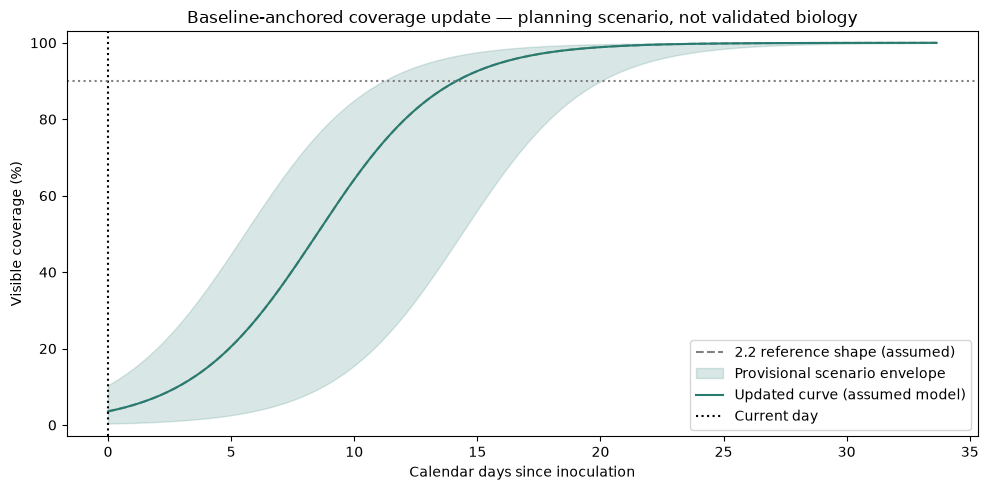

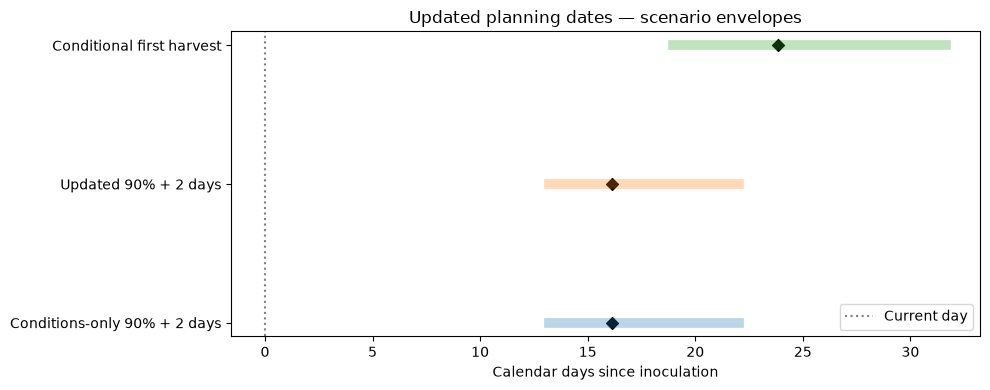

In [7]:
figures={}
finite_dates=[CURRENT_DAY+7.,float(REFERENCE_T90[2])+POST_90_DAYS]
for values in [forecast['t90_day_min_typ_max'],forecast['first_harvest_day_min_typ_max']]:
    if values is not None:finite_dates.append(float(values[2])+2)
horizon=min(max(finite_dates),max(365.,float(REFERENCE_T90[2])*3))
grid=np.linspace(0,horizon,350)
base_slope=LOG9/((1-UPDATE_RULES['curve_midpoint_fraction'])*REFERENCE_T90[1])
fig,ax=plt.subplots(figsize=(10,5))
base=logistic_coverage(grid,REFERENCE_T90[1],base_slope)
ax.plot(grid,100*base,'--',color='grey',label='2.2 reference shape (assumed)')
clock=[]
for day in grid:
    if day<=CURRENT_DAY:tau=effective_clock(float(day),condition_history)
    else:
        origin=effective_clock(CURRENT_DAY,condition_history);rate=effective_rate(future_conditions)
        tau=None if origin is None or rate is None else origin+(day-CURRENT_DAY)*rate
    clock.append(np.full(3,np.nan) if tau is None else tau)
clock=np.array(clock)
fit=forecast['curve_fit']
if fit['scale_scenarios'] is not None:
    curves=np.column_stack([logistic_coverage(clock[:,q],REFERENCE_T90[q]*fit['scale_scenarios'][q],fit['slope']) for q in range(3)])
    valid = np.isfinite(curves).all(axis=1)
    curve_low = np.full(len(grid), np.nan); curve_high = curve_low.copy()
    curve_low[valid] = curves[valid].min(axis=1); curve_high[valid] = curves[valid].max(axis=1)
    ax.fill_between(grid,100*curve_low,100*curve_high,alpha=.18,color='#287c6f',label='Provisional scenario envelope')
    ax.plot(grid,100*curves[:,1],color='#287c6f',label='Updated curve (assumed model)')
if coverage:
    ax.errorbar([r['day'] for r in coverage],[r['coverage_pct'] for r in coverage],
                yerr=[100*r['uncertainty_fraction'] for r in coverage],fmt='o',color='#a85d25',capsize=3,label='Entered coverage / tolerance')
ax.axvline(CURRENT_DAY,color='black',ls=':',label='Current day');ax.axhline(90,color='grey',ls=':')
ax.set(xlabel='Calendar days since inoculation',ylabel='Visible coverage (%)',ylim=(-3,103),
       title='Baseline-anchored coverage update — planning scenario, not validated biology')
ax.legend(loc='lower right');fig.tight_layout();figures['coverage_update']=fig;plt.show()

fig,ax=plt.subplots(figsize=(10,4))
shown=[(name,vals) for name,vals in [('Conditions-only 90% + 2 days',None if forecast['conditions_only_t90_day_min_typ_max'] is None else [v+POST_90_DAYS for v in forecast['conditions_only_t90_day_min_typ_max']]),
                                   ('Updated 90% + 2 days',forecast['planning_90_plus_2_day_min_typ_max']),
                                   ('Conditional first harvest',forecast['first_harvest_day_min_typ_max'])] if vals is not None]
for i,(name,vals) in enumerate(shown):
    ax.plot([vals[0],vals[2]],[i,i],lw=7,alpha=.3);ax.scatter(vals[1],i,color='black',marker='D')
ax.axvline(CURRENT_DAY,color='grey',ls=':',label='Current day');ax.set_yticks(range(len(shown)),[name for name,_ in shown])
ax.set(xlabel='Calendar days since inoculation',title='Updated planning dates — scenario envelopes');ax.legend()
fig.tight_layout();figures['updated_dates']=fig;plt.show()
if fit['profile'] is not None:
    fig,ax=plt.subplots(figsize=(8,3))
    ax.plot(fit['profile']['scale'],fit['profile']['loss']);ax.set_xscale('log')
    ax.set(xlabel='90% duration / reference duration',ylabel='Penalised mismatch score',title='Photo/prior trade-off — not a calibrated likelihood')
    fig.tight_layout();figures['curve_profile']=fig;plt.show()

## 7. Software checks (artificial fixtures only)

The following deliberately constructed records check arithmetic and failure handling. They are not experimental results and are never exported as batch observations. No d005, syldd or d0xx data are fitted here. Source-file and model-bundle hashes must remain unchanged.

In [8]:
checks=[]
def checked(name,condition):
    assert bool(condition),name
    checks.append(name)

def must_reject(name,fn):
    try:fn()
    except (ValueError,TypeError):checks.append(name)
    else:raise AssertionError(name)

# Use the selected reference's optimum core scenario to exercise arithmetic for every supported species.
fixture_conditions={'temperature_c':float(reference.incubation_temp_opt_C),'temperature_basis':'substrate_core',
                    'humidity_pct':None,'drying_exposed':True}
fixture_history=[{'day':0.,'conditions':fixture_conditions,'origin':'recorded update'}]
reference_effect=condition_effects(fixture_conditions,reference,species)
constant_expected=REFERENCE_T90*reference_effect['factor']+reference_effect['delay']
r=forecast_batch([],fixture_history,fixture_conditions,0.)
checked('conditions-only forecast reproduces 2.2 constant-condition arithmetic',np.allclose(r['t90_day_min_typ_max'],constant_expected))
checked('post-90 two-day allowance added once',np.allclose(np.array(r['planning_90_plus_2_day_min_typ_max'])-r['t90_day_min_typ_max'],POST_90_DAYS))
slow={**fixture_conditions,'temperature_c':float(reference.incubation_temp_opt_C)-4.}
slow_rate=effective_rate(slow);fast_rate=effective_rate(fixture_conditions)
h=[{'day':0.,'conditions':fixture_conditions,'origin':'recorded update'}, {'day':2.,'conditions':slow,'origin':'recorded update'}]
checked('condition change affects only the subsequent interval',np.allclose(effective_clock(3.,h),2*fast_rate+slow_rate))
checked('future condition changes do not rewrite historical exposure',np.allclose(effective_clock(2.,h),2*fast_rate))
lo=forecast_batch([],h,slow,3.)
expected=3.+(REFERENCE_T90-(2*fast_rate+slow_rate))/slow_rate
if (expected>=3).all():checked('piecewise future extrapolation arithmetic',np.allclose(lo['t90_day_min_typ_max'],sorted(expected)))
obs,_=prepare_coverage([{'day':2.,'coverage_pct':40.},{'day':4.,'coverage_pct':92.}],4.)
cross,basis=observed_crossing(obs,None,4.)
checked('90% crossing is a bracket, not the first photo date',[float(v) for v in cross]==[2.,3.,4.])
obs_late,_=prepare_coverage([{'day':10.,'coverage_fraction':.95}],10.)
checked('first late photo does not invent an exact crossing',observed_crossing(obs_late,None,10.)[0]==[0.,5.,10.])
checked('confirmed crossing overrides bracket',observed_crossing(obs,3.5,4.)[0]==[3.5,3.5,3.5])
observed=forecast_batch(obs,fixture_history,fixture_conditions,4.)
checked('observed bracket adds allowance once',observed['planning_90_plus_2_day_min_typ_max']==[2.+POST_90_DAYS,3.+POST_90_DAYS,4.+POST_90_DAYS])
accepted,rejected=prepare_coverage([{'day':1.,'coverage_pct':20.,'quality_ok':False}],1.)
checked('poor-quality measurement excluded but retained in audit',len(accepted)==0 and len(rejected)==1)
roundtrip,_=prepare_coverage([{'day':1.,'coverage_pct':20.,'uncertainty_fraction':.07}],1.)
checked('exported fractional measurement tolerance survives reload',roundtrip[0]['uncertainty_fraction']==.07)
for name,records,day in [
 ('future photo rejected',[{'day':3,'coverage_pct':20}],2),
 ('percentage out of bounds rejected',[{'day':1,'coverage_pct':120}],2),
 ('ambiguous units rejected',[{'day':1,'coverage':.2}],2),
 ('duplicate photo time rejected',[{'day':1,'coverage_pct':20},{'day':1,'coverage_pct':30}],2),
 ('duplicate photo identifier rejected',[{'day':1,'coverage_pct':20,'photo_id':'x'},{'day':2,'coverage_pct':30,'photo_id':'x'}],2)]:
    must_reject(name,lambda records=records,day=day:prepare_coverage(records,day))
must_reject('future condition record rejected',lambda:prepare_conditions([{'day':3,'temperature_c':20}],2,fixture_conditions))
must_reject('date/day mismatch rejected',lambda:record_day({'day':1,'date':'2026-10-03'},'2026-10-01'))
checked('date correctly converted to elapsed day',record_day({'date':'2026-10-03'},'2026-10-01')==2.)
stalled,_=prepare_coverage([{'day':1,'coverage_pct':20},{'day':3,'coverage_pct':21},{'day':5,'coverage_pct':21}],5.)
checked('stalled sequence not given a finite photo forecast',forecast_batch(stalled,fixture_history,fixture_conditions,5.)['t90_day_min_typ_max'] is None)
declining,_=prepare_coverage([{'day':1,'coverage_pct':60},{'day':3,'coverage_pct':30}],3.)
checked('large decline requires review',fit_progress(declining,fixture_history,3.)['status']=='declining_coverage_review')
unknown={**fixture_conditions,'temperature_basis':'unknown'}
checked('unknown basis does not become core temperature',forecast_batch([],fixture_history,unknown,1.)['t90_day_min_typ_max'] is None)
independent=forecast_batch([],fixture_history,unknown,1.,induction_day=10.)
checked('actual induction independently anchors harvest',np.allclose(independent['first_harvest_day_min_typ_max'],10.+HARVEST_STAGE))
checked('negative remaining values are clipped, not readiness proof',forecast_batch([],fixture_history,fixture_conditions,1000.)['planning_days_remaining']==[0.,0.,0.])
# Known faster trajectory generated solely for algorithm verification; never added to actual coverage.
fixture_days=REFERENCE_T90[1]*np.array([.15,.3,.45])
fixture_t90=REFERENCE_T90[1]*.70
fixture_slope=LOG9/((1-UPDATE_RULES['curve_midpoint_fraction'])*fixture_t90)
fixture=[]
for day in fixture_days:
    tau=effective_clock(float(day),fixture_history)[1]
    fixture.append({'day':float(day),'coverage_fraction':float(logistic_coverage(tau,fixture_t90,fixture_slope)),
                    'uncertainty_fraction':.07,'coverage_pct':float(100*logistic_coverage(tau,fixture_t90,fixture_slope)),
                    'quality_ok':True,'photo_id':None})
fast_fit=fit_progress(fixture,fixture_history,float(fixture_days[-1]))
checked('informative faster photos move fitted crossing earlier',fast_fit['scale_scenarios'] is not None and fast_fit['scale_scenarios'][1]<1.)
checked('scenario envelope remains ordered',all(np.diff(fast_fit['scale_scenarios'])>=0))
checked('2.2 bundle inputs unchanged',all(sha256(path)==digest for path,digest in input_hashes.items()))
checked('source references unchanged',all(sha256(path)==digest for path,digest in original_hashes.items()))
print(f'{len(checks)} software checks passed; no biological validation claimed.')

28 software checks passed; no biological validation claimed.


## 8. Save the update and its inputs

A new `forecast_update_*` folder is created inside `models/colonisation/` for each run. It contains the normalized accepted and rejected observations, condition/exposure history, current/future assumptions, forecast, model provenance, figures and check results. The forecast never silently changes the 2.2 bundle or the source files.

**Next dependency:** improve 2.4 to export batch ID, day/date, explicit coverage units, photo identity and quality metadata. Then point `COVERAGE_CSV` here to that output. Until then, manual/corrected measurements can exercise the entire update flow. Actual induction starts the harvest clock; post-induction environmental and fruiting-photo updates remain a separate task.

In [9]:
run_dir=None
if WRITE_OUTPUTS:
    run_id='forecast_update_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    run_dir=output_path(Path('models/colonisation')/run_id)
    run_dir.mkdir(parents=True,exist_ok=False)
    summary.to_csv(run_dir/'forecast_summary.csv',index=False)
    pd.DataFrame(coverage,columns=['day','coverage_fraction','coverage_pct','photo_id','quality_ok','uncertainty_fraction']).to_csv(run_dir/'accepted_coverage.csv',index=False)
    pd.DataFrame(rejected_coverage,columns=['day','coverage_fraction','coverage_pct','photo_id','quality_ok','uncertainty_fraction','reason']).to_csv(run_dir/'rejected_coverage.csv',index=False)
    exposure_audit.to_csv(run_dir/'exposure_audit.csv',index=False)
    artifacts={
        'forecast.json':{'batch_id':BATCH['batch_id'],'species':species,'substrate':substrate,**forecast},
        'input_records.json':{'batch':BATCH,'coverage_records':coverage_input,'condition_records':condition_input,
                              'normalized_conditions':condition_history,'future_conditions':future_conditions,
                              'other_batch_records_excluded':excluded_coverage_batches+excluded_condition_batches},
        'provenance.json':{'producer':'2.5.colonisation_forecast_updater','baseline_bundle':str(bundle_dir),
                           'reference_id':reference.ref_id,'input_hashes':input_hashes,'source_hashes':original_hashes,
                           'experimental_training_or_validation':False},
        'update_rules.json':UPDATE_RULES,'inherited_2_2_settings.json':settings,'software_checks.json':checks,
    }
    for name,value in artifacts.items():(run_dir/name).write_text(json.dumps(clean_json(value),indent=2,allow_nan=False)+'\n')
    for name,fig in figures.items():fig.savefig(run_dir/f'{name}.png',dpi=150,bbox_inches='tight')
    (run_dir/'notes.md').write_text(
        '# Forecast update\n\nConsensus baseline plus provisional environment/progress rules. '
        'Scenario ranges are not confidence intervals. No d0xx fit or validation. '
        'No automatic image processing in 2.5: entered coverage must come from manual review or 2.4. '
        'Past condition intervals are integrated; future conditions are a separate fixed scenario. '
        'Two calendar days are added once to the 90% crossing. Harvest uses a separate conditional stage duration.\n')
    assert all(sha256(path)==digest for path,digest in input_hashes.items())
    assert all(sha256(path)==digest for path,digest in original_hashes.items())
    print('Saved update bundle:',run_dir)
else:print('WRITE_OUTPUTS=False; no update bundle saved.')

Saved update bundle: /home/sylas/Desktop/mycodemo/models/colonisation/forecast_update_20261019T100104_177367Z
